Split already exists
Using device: cpu
Classes: ['Normal', 'high_risk', 'low_risk', 'moderate']
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\Admin/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100.0%


Epoch 1, Loss: 82.87, Val Acc: 0.4015
Epoch 2, Loss: 62.46, Val Acc: 0.5235
Epoch 3, Loss: 52.80, Val Acc: 0.5666
Epoch 4, Loss: 49.45, Val Acc: 0.5553
Epoch 5, Loss: 45.19, Val Acc: 0.5929
Unfreezing model for fine-tuning...
Epoch 6, Loss: 33.39, Val Acc: 0.7392
Epoch 7, Loss: 22.93, Val Acc: 0.7711
Epoch 8, Loss: 17.87, Val Acc: 0.8255
Epoch 9, Loss: 13.65, Val Acc: 0.8049
Epoch 10, Loss: 12.20, Val Acc: 0.8143

TRAIN REPORT:

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99       380
   high_risk       0.94      0.92      0.93       373
    low_risk       0.98      0.95      0.97       595
    moderate       0.90      0.94      0.92       520

    accuracy                           0.95      1868
   macro avg       0.95      0.95      0.95      1868
weighted avg       0.95      0.95      0.95      1868


TEST REPORT:

              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99        55
   high_

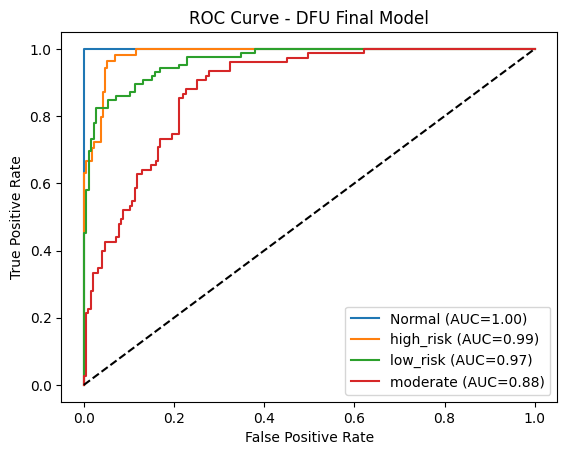


Training Complete ✅


In [ ]:
# =========================
# FINAL DFU MODEL (IMPROVED)
# =========================

import os
import random
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# =========================
# 1. PATHS
# =========================
source_dir = "D:/Dia Foot/DFU/Classification Folder"
split_dir = "D:/Dia Foot/DFU/DFU_split"

# =========================
# 2. SPLIT DATA (70/20/10)
# =========================
if not os.path.exists(split_dir):
    print("Splitting dataset...")

    for cls in os.listdir(source_dir):
        images = os.listdir(os.path.join(source_dir, cls))
        random.shuffle(images)

        n = len(images)
        train_split = int(0.7 * n)
        val_split = int(0.9 * n)

        splits = {
            "train": images[:train_split],
            "val": images[train_split:val_split],
            "test": images[val_split:]
        }

        for split in splits:
            path = os.path.join(split_dir, split, cls)
            os.makedirs(path, exist_ok=True)

            for img in splits[split]:
                shutil.copy(
                    os.path.join(source_dir, cls, img),
                    os.path.join(path, img)
                )

    print("Dataset split done!")
else:
    print("Split already exists")

# =========================
# 3. DEVICE
# =========================
device = torch.device("cpu")
print("Using device:", device)

# =========================
# 4. TRANSFORMS
# =========================
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# =========================
# 5. LOAD DATA
# =========================
train_data = datasets.ImageFolder(split_dir + "/train", transform=transform_train)
val_data   = datasets.ImageFolder(split_dir + "/val", transform=transform_val)
test_data  = datasets.ImageFolder(split_dir + "/test", transform=transform_val)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=16, shuffle=False)

class_names = train_data.classes
print("Classes:", class_names)

# =========================
# 6. MODEL (MobileNetV2)
# =========================
model = models.mobilenet_v2(pretrained=True)
model.classifier[1] = nn.Linear(model.last_channel, 4)
model = model.to(device)

# =========================
# 7. FOCAL LOSS
# =========================
class FocalLoss(nn.Module):
    def __init__(self, gamma=2):
        super(FocalLoss, self).__init__()
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        loss = (1 - pt) ** self.gamma * ce_loss
        return loss.mean()

criterion = FocalLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# =========================
# 8. FREEZE BACKBONE (STAGE 1)
# =========================
for param in model.features.parameters():
    param.requires_grad = False

# =========================
# 9. TRAINING
# =========================
epochs = 10
best_val_acc = 0

for epoch in range(epochs):

    # UNFREEZE AFTER 5 EPOCHS
    if epoch == 5:
        for param in model.parameters():
            param.requires_grad = True
        print("Unfreezing model for fine-tuning...")

    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # VALIDATION
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images.to(device))
            _, preds = torch.max(outputs, 1)

            correct += (preds.cpu() == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total
    print(f"Epoch {epoch+1}, Loss: {total_loss:.2f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_dfu_final.pth")

# =========================
# 10. TRAIN REPORT
# =========================
model.eval()
train_preds, train_labels = [], []

with torch.no_grad():
    for images, labels in train_loader:
        outputs = model(images.to(device))
        _, preds = torch.max(outputs, 1)

        train_preds.extend(preds.cpu().numpy())
        train_labels.extend(labels.numpy())

print("\nTRAIN REPORT:\n")
print(classification_report(train_labels, train_preds, target_names=class_names))

# =========================
# 11. TEST REPORT + PROBS
# =========================
model.load_state_dict(torch.load("best_dfu_final.pth"))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

print("\nTEST REPORT:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# =========================
# 12. ROC + AUC
# =========================
y_true = np.array(all_labels)
y_score = np.array(all_probs)

y_true_bin = label_binarize(y_true, classes=[0,1,2,3])

plt.figure()

for i in range(4):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DFU Final Model")
plt.legend()
plt.show()

print("\nTraining Complete ✅")